# 01 — Per-source EDA: Pudding film dialogue (Phase 2)

**Scope:** the two Pudding files in isolation — no joins, no other sources.
Goal is to understand shape, types, coverage, and quirks *before* the Phase 3
aggregation to film grain, and to record anything that changes the plan.

**Inputs (read-only):**
- `data/raw/pudding_character_list5.csv` — CHARACTER grain: `script_id`, `imdb_character_name`, `words`, `gender`, `age`
- `data/raw/pudding_meta_data7.csv` — FILM grain: `script_id`, `imdb_id`, `title`, `year`, `gross` (inflation-adjusted domestic, $M), `lines_data`

**Questions this notebook must answer:**
1. Is `script_id` a clean key on both sides (unique in meta, valid FK from characters)?
2. Is `imdb_id` unique in meta (it's our join key to Bechdel later)?
3. Year coverage — how many films survive the 1990–2015 filter?
4. Missingness — where, how much, and does it correlate with anything (esp. `gross`)?
5. Distributions of `words`, characters-per-film, `gross` — skew we must handle later?
6. Gender coding — categories, the `?` rows, films with zero speaking women.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = Path.cwd().parent / "data" / "raw"
FIGS = Path.cwd().parent / "figures"

# latin-1: these files contain non-UTF-8 bytes (accented character names)
chars = pd.read_csv(RAW / "pudding_character_list5.csv", encoding="latin-1")
meta = pd.read_csv(RAW / "pudding_meta_data7.csv", encoding="latin-1")

print(f"chars: {chars.shape}")
print(f"meta : {meta.shape}")

chars: (23048, 5)
meta : (2000, 6)


## 1. meta_data7 — the film-level table

First contact: dtypes, head, and basic uniqueness. `script_id` and `imdb_id`
both need to be trustworthy keys — `script_id` to attach the character
aggregates (Phase 3), `imdb_id` to join Bechdel (Phase 4).

In [2]:
meta.info()
meta.head()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   script_id   2000 non-null   int64  
 1   imdb_id     2000 non-null   str    
 2   title       2000 non-null   str    
 3   year        2000 non-null   int64  
 4   gross       1662 non-null   float64
 5   lines_data  2000 non-null   object 
dtypes: float64(1), int64(2), object(1), str(2)
memory usage: 93.9+ KB


,script_id,imdb_id,title,year,gross,lines_data
0,1534,tt1022603,(500) Days of Summer,2009,37.0,7435445256774774443342577775657744434444564456...
1,1512,tt0147800,10 Things I Hate About You,1999,65.0,1777752320274533344457777722433777334443764677...
2,1514,tt0417385,12 and Holding,2005,NaN,5461357777754212454544441367774433446547647753...
3,1517,tt2024544,12 Years a Slave,2013,60.0,4567334777777777777777447777756477777444777777...
4,1520,tt1542344,127 Hours,2010,20.0,453513352345765766777777773340


In [3]:
print("script_id unique in meta:", meta["script_id"].is_unique)
print("imdb_id  unique in meta:", meta["imdb_id"].is_unique)

# any duplicated imdb_ids are a problem for the Bechdel join — look at them now
dupes = meta[meta["imdb_id"].duplicated(keep=False)].sort_values("imdb_id")
print(f"rows sharing an imdb_id: {len(dupes)}")
dupes[["script_id", "imdb_id", "title", "year", "gross"]]

script_id unique in meta: True
imdb_id  unique in meta: True
rows sharing an imdb_id: 0


,script_id,imdb_id,title,year,gross


In [4]:
# imdb_id format check: all should match tt + 7 digits (already normalized,
# unlike the Bechdel side which we'll have to pad)
pattern_ok = meta["imdb_id"].str.fullmatch(r"tt\d{7}")
print(f"imdb_id matching tt+7digits: {pattern_ok.sum()} / {len(meta)}")
meta.loc[~pattern_ok, ["script_id", "imdb_id", "title", "year"]]

imdb_id matching tt+7digits: 2000 / 2000


,script_id,imdb_id,title,year


### Year coverage

The project window is **1990–2015**. Everything before 1990 drops out in
Phase 4 — this is where we learn how much sample that costs.

count    2000.000000
mean     1998.103000
std        14.810708
min      1929.000000
25%      1992.000000
50%      2001.000000
75%      2009.000000
max      2015.000000
Name: year, dtype: float64

films in 1990-2015: 1587 of 2000 (79%)


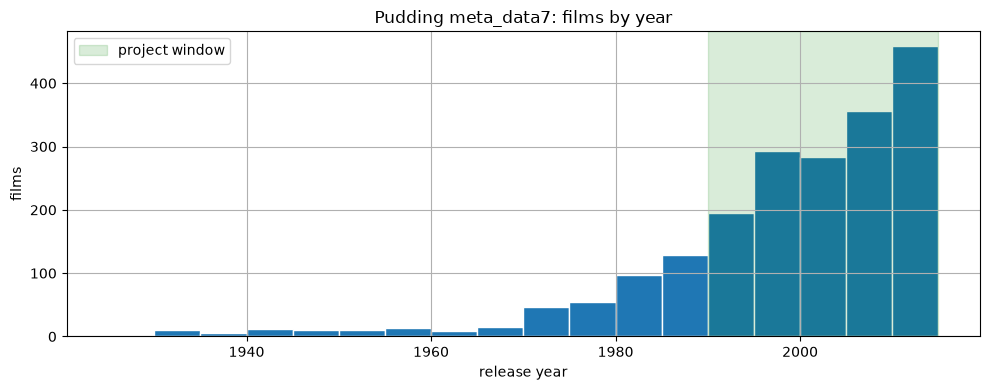

In [5]:
in_window = meta["year"].between(1990, 2015)
print(meta["year"].describe())
print(f"\nfilms in 1990-2015: {in_window.sum()} of {len(meta)} ({in_window.mean():.0%})")

fig, ax = plt.subplots(figsize=(10, 4))
meta["year"].hist(bins=range(1925, 2020, 5), ax=ax, edgecolor="white")
ax.axvspan(1990, 2015, alpha=0.15, color="green", label="project window")
ax.set_xlabel("release year")
ax.set_ylabel("films")
ax.set_title("Pudding meta_data7: films by year")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "eda_pudding_year_coverage.png", dpi=150)
plt.show()

### Missingness and the `gross` column

`gross` is inflation-adjusted domestic gross in $M (2016 basis, per The
Pudding's write-up). Two things to check:
1. How much is missing, and
2. whether missingness is *systematic by year* — if older films are more
   likely to lack gross, dropping them interacts with our year filter.

In [6]:
print(meta.isna().sum())
print()
print("gross missing overall :", f"{meta['gross'].isna().mean():.1%}")
print("gross missing in-window:", f"{meta.loc[in_window, 'gross'].isna().mean():.1%}")

# missingness by era — systematic?
meta.assign(era=pd.cut(meta["year"], [1925, 1970, 1990, 2000, 2010, 2016]))\
    .groupby("era", observed=True)["gross"].apply(lambda s: s.isna().mean())

script_id       0
imdb_id         0
title           0
year            0
gross         338
lines_data      0
dtype: int64

gross missing overall : 16.9%
gross missing in-window: 9.4%


era
(1925, 1970]    0.815217
(1970, 1990]    0.322946
(1990, 2000]    0.046332
(2000, 2010]    0.113602
(2010, 2016]    0.133152
Name: gross, dtype: float64

count    1438.000000
mean       92.920723
std       118.138322
min         0.000000
25%        19.000000
50%        50.000000
75%       121.000000
max      1249.000000
Name: gross, dtype: float64


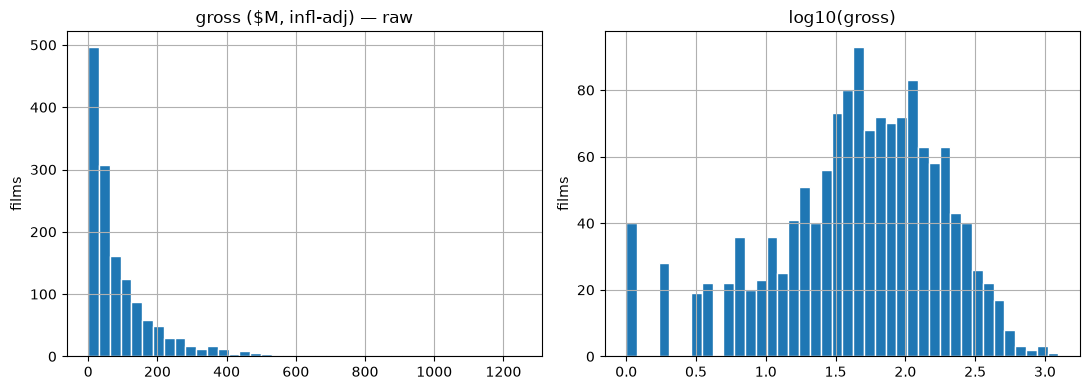

In [7]:
# distribution of gross (in-window films only) — expect heavy right skew;
# this previews the need for a log transform in the analysis phase
gross_iw = meta.loc[in_window, "gross"].dropna()
print(gross_iw.describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
gross_iw.hist(bins=40, ax=axes[0], edgecolor="white")
axes[0].set_title("gross ($M, infl-adj) — raw")
np.log10(gross_iw[gross_iw > 0]).hist(bins=40, ax=axes[1], edgecolor="white")
axes[1].set_title("log10(gross)")
for ax in axes:
    ax.set_ylabel("films")
fig.tight_layout()
fig.savefig(FIGS / "eda_pudding_gross_dist.png", dpi=150)
plt.show()

## 2. character_list5 — the character-level table

In [8]:
chars.info()
chars.head()

<class 'pandas.DataFrame'>
RangeIndex: 23048 entries, 0 to 23047
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   script_id            23048 non-null  int64  
 1   imdb_character_name  23046 non-null  str    
 2   words                23048 non-null  int64  
 3   gender               23048 non-null  str    
 4   age                  18263 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 900.4 KB


,script_id,imdb_character_name,words,gender,age
0,280,betty,311,f,35.0
1,280,carolyn johnson,873,f,NaN
2,280,eleanor,138,f,NaN
3,280,francesca johns,2251,f,46.0
4,280,madge,190,f,46.0


In [9]:
print("gender counts:")
print(chars["gender"].value_counts(dropna=False))
print()
# the '?' rows — few enough to inspect individually; decide drop vs. keep
chars[chars["gender"] == "?"]

gender counts:
gender
m    16132
f     6911
?        5
Name: count, dtype: int64



,script_id,imdb_character_name,words,gender,age
7325,2510,tiny tim,488,?,NaN
8010,2682,himself - walki,312,?,90.0
8011,2682,himself - with,224,?,78.0
16902,6053,Thomas Hergenro,216,?,NaN
18812,7177,randy,167,?,NaN


In [10]:
print("missingness:")
print(chars.isna().sum())
print()
print("age summary (note: Pudding docs say age was scraped where available):")
print(chars["age"].describe())
# implausible ages are a known quirk in this file — count them rather than trust min/max
print("\nage > 100:", (chars["age"] > 100).sum(), "| age <= 0:", (chars["age"] <= 0).sum())

missingness:
script_id                 0
imdb_character_name       2
words                     0
gender                    0
age                    4785
dtype: int64

age summary (note: Pudding docs say age was scraped where available):
count    18263.000000
mean        42.382960
std         59.718859
min          3.000000
25%         30.000000
50%         39.000000
75%         50.000000
max       2013.000000
Name: age, dtype: float64

age > 100: 17 | age <= 0: 0


count    23048.000000
mean       907.871486
std       1399.593759
min        101.000000
25%        193.000000
50%        396.000000
75%        980.000000
max      28102.000000
Name: words, dtype: float64


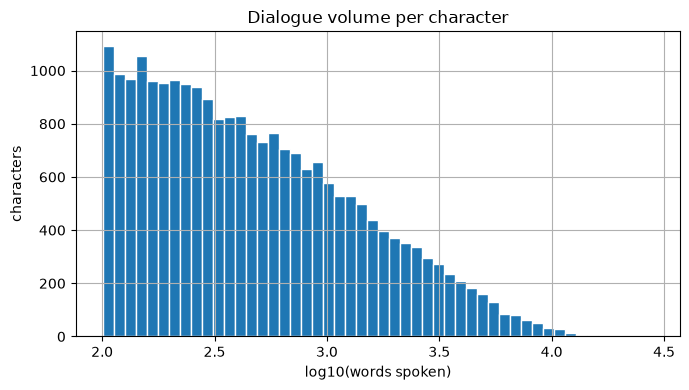

characters with words <= 0 or NaN: 0


In [11]:
# words per character — expect extreme right skew (leads vs. bit parts)
print(chars["words"].describe())

fig, ax = plt.subplots(figsize=(7, 4))
np.log10(chars.loc[chars["words"] > 0, "words"]).hist(bins=50, ax=ax, edgecolor="white")
ax.set_xlabel("log10(words spoken)")
ax.set_ylabel("characters")
ax.set_title("Dialogue volume per character")
fig.tight_layout()
fig.savefig(FIGS / "eda_pudding_words_dist.png", dpi=150)
plt.show()

# words == 0 or missing would break pct_female_dialogue denominators — check
print("characters with words <= 0 or NaN:", ((chars["words"] <= 0) | chars["words"].isna()).sum())

count    2000.000000
mean       11.524000
std         4.466811
min         2.000000
25%         8.000000
50%        11.000000
75%        14.000000
max        40.000000
dtype: float64


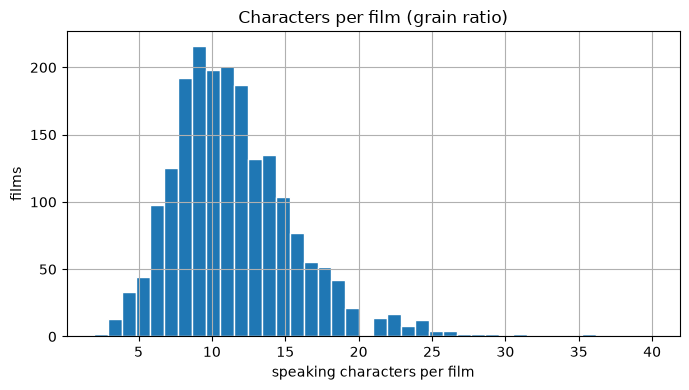

In [12]:
# characters per film — the grain ratio, and a preview of Phase 3 output size
per_film = chars.groupby("script_id").size()
print(per_film.describe())

fig, ax = plt.subplots(figsize=(7, 4))
per_film.hist(bins=40, ax=ax, edgecolor="white")
ax.set_xlabel("speaking characters per film")
ax.set_ylabel("films")
ax.set_title("Characters per film (grain ratio)")
fig.tight_layout()
fig.savefig(FIGS / "eda_pudding_chars_per_film.png", dpi=150)
plt.show()

## 3. Cross-file key integrity (still one source — no external joins)

`script_id` must connect the two files cleanly for the Phase 3 aggregation:
every character row should point at a film in meta, and (nearly) every film
should have character rows.

In [13]:
char_ids = set(chars["script_id"])
meta_ids = set(meta["script_id"])

print(f"script_ids in chars only (orphan characters): {len(char_ids - meta_ids)}")
print(f"script_ids in meta only (films w/o characters): {len(meta_ids - char_ids)}")
print(f"script_ids in both: {len(char_ids & meta_ids)}")

# if either set is small, list them — they become documented exclusions
if 0 < len(meta_ids - char_ids) <= 20:
    display(meta[meta["script_id"].isin(meta_ids - char_ids)][["script_id", "imdb_id", "title", "year"]])

script_ids in chars only (orphan characters): 0
script_ids in meta only (films w/o characters): 0
script_ids in both: 2000


count    2000.000000
mean        0.282527
std         0.197047
min         0.000000
25%         0.134691
50%         0.242742
75%         0.389299
max         1.000000
dtype: float64

films with ZERO female dialogue: 54 of 2000


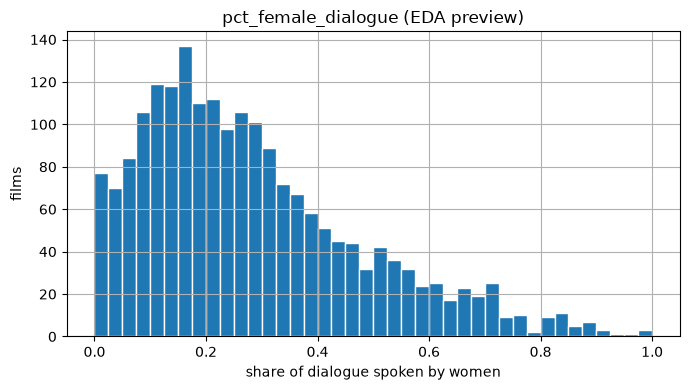

In [14]:
# preview of the Phase 3 headline metric: % of films with zero speaking women
# (computed here only as an EDA fact, not persisted — Phase 3 owns the real aggregation)
fem_words = chars.assign(is_f=chars["gender"].eq("f"))\
    .groupby("script_id")\
    .apply(lambda g: g.loc[g["is_f"], "words"].sum() / g["words"].sum(), include_groups=False)

print(fem_words.describe())
print(f"\nfilms with ZERO female dialogue: {(fem_words == 0).sum()} of {len(fem_words)}")

fig, ax = plt.subplots(figsize=(7, 4))
fem_words.hist(bins=40, ax=ax, edgecolor="white")
ax.set_xlabel("share of dialogue spoken by women")
ax.set_ylabel("films")
ax.set_title("pct_female_dialogue (EDA preview)")
fig.tight_layout()
fig.savefig(FIGS / "eda_pudding_pct_female_dialogue.png", dpi=150)
plt.show()

## 4. Findings log

*Fill this in as you run — these notes feed the Phase 3 spec and the final
limitations section. Prompts:*

- **Keys:** script_id unique? imdb_id unique? Any malformed ids? → consequences for Phases 3–4: all unique
- **Window:** films surviving 1990–2015 filter: 1587
- **gross:** % missing in-window: 9.4 ; missingness pattern by era:
- **gender `?` rows (5):** decision: drop / recode — and why: Tiny Tim : M; himself - walki : drop; himself - with : drop; Thomas Hergenro : M; randy : M;
- **age:** usable or too gappy? (we don't need it for the core metrics): usable
- **Skew:** gross and words both right-skewed → log-scale plots / transforms downstream
- **Range restriction seen already:** min in-window gross is ____ $M — confirms the
  "already-successful films" caveat from the project brief
- **Surprises:**

In [15]:
import requests
r = requests.get(
    "https://www.the-numbers.com/movie/budgets/all",
    headers={"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 13_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/16.6 Safari/605.1.15"},
    timeout=30,
)
print(r.status_code, len(r.content), "bytes")

SSLError: HTTPSConnectionPool(host='www.the-numbers.com', port=443): Max retries exceeded with url: /movie/budgets/all (Caused by SSLError(SSLEOFError(8, '[SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1028)')))